# Fresnel compensation: uniform illumination versus a prepared pupil

**Question.** Can a spatially varying incident polarization and amplitude remove the *effect* of unequal Fresnel transmission from a focal field? What does that recovery cost at fixed incident power?

We compare three fields through the **same aperture and ideal aplanatic objective**:

1. A reference objective with no interface loss, illuminated with constant amplitude and circular polarization.
2. The objective with an angular Fresnel pupil, illuminated with that **same constant amplitude**.
3. The same Fresnel pupil, with analytically prepared illumination carrying **the same incident power**.

The interface is an ideal lossless high-index dielectric–air boundary, with $n_o=2.4$ and $n_i=1$. The image NA is 0.995, deliberately close to the grazing transmitted direction. Its Fresnel response is prescribed as the pupil of an ideal objective. This is a controlled angular-pupil experiment, not a surface prescription for a particular lens. Intensity maps use inferno; polarization glyphs use grayscale.

## 1. Transmission and the correct power measure

At each pupil radius the aplanatic sine condition gives $\rho=f\sin\theta_i$. Snell's law determines the incident angle:

$$
 n_o\sin\theta_o=n_i\sin\theta_i,\qquad
 c_o=\cos\theta_o,\quad c_i=\cos\theta_i.
$$

The **electric-amplitude** coefficients are

$$
 t_s=\frac{2n_o c_o}{n_o c_o+n_i c_i},\qquad
 t_p=\frac{2n_o c_o}{n_i c_o+n_o c_i}.
$$

For a plane wave the normal flux is $n c\,|E|^2/(2Z_0)$. The ideal focusing operator already transports power between its pupil and image directions. Its additional transmission multipliers must therefore be

$$
 \tau_j=t_j\sqrt{\frac{n_i c_i}{n_o c_o}},\qquad
 T_j=|\tau_j|^2,\qquad R_j+T_j=1.
$$

This conversion is essential: multiplying the ideal, power-preserving pupil operator by raw $t_j$ would apply the flux Jacobian incorrectly. At normal incidence both channels agree. At grazing transmission $\tau_j\to0$; attempting an exact inverse there becomes unbounded. The full circular pupil reaches the selected NA, which stays below that limit. The index 2.4 is an explicitly ideal, nonabsorbing material model, not a claim about a particular fabricated objective. Brewster incidence cancels $r_p$, not $t_p$.

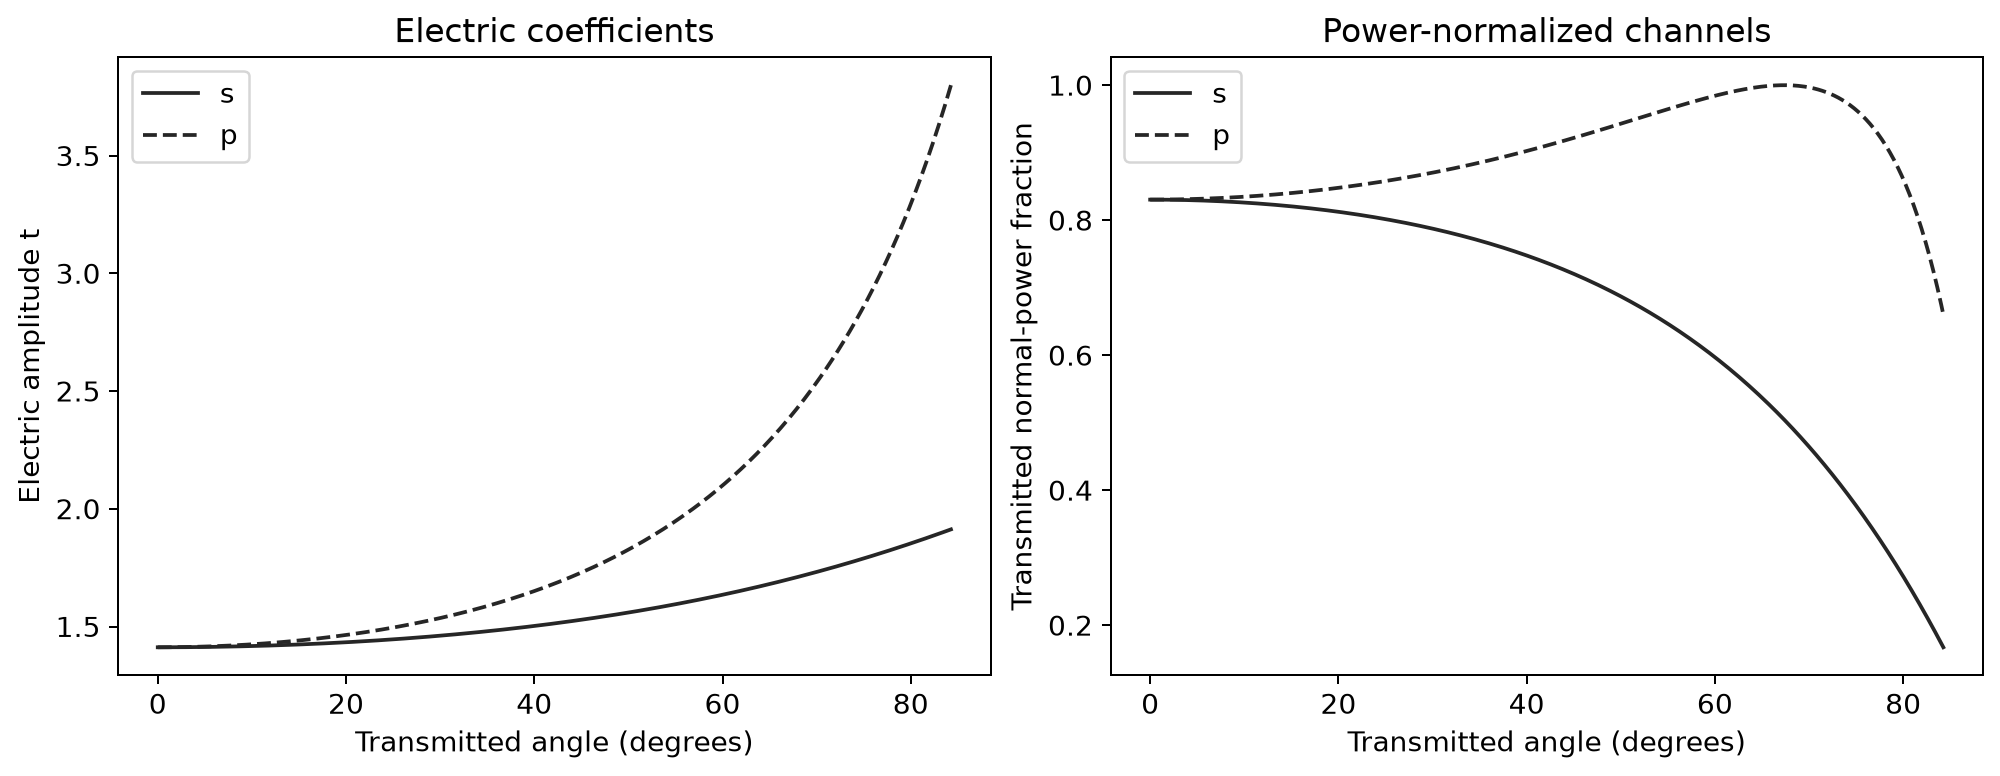

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import vecdiff_general as optics
from matplotlib.colors import ListedColormap, Normalize
from scipy.special import j1
from vecdiff_general.interfaces.fresnel import (
    reflection_coefficients,
    transmission_coefficients,
)
from vecdiff_general.propagation.imaging import focus_pupil
from vecdiff_general.visualization import plot_intensity

%matplotlib inline

plt.rcParams.update({"figure.dpi": 180, "font.size": 11})
# Preserve inferno above zero and give zero intensity an exact black endpoint.
colors = plt.colormaps["inferno"](np.linspace(0, 1, 256))
colors[0, :3] = 0
intensity_cmap = ListedColormap(colors, name="inferno_black")

um = 1e-6
wavelength = 532e-9
focal_length = 20 * um
numerical_aperture = 0.995
incident_power = 1e-12
no, ni = 2.4, 1.0
high_index = optics.HomogeneousRegion(
    "ideal high-index dielectric", optics.Dielectric(no)
)
air = optics.HomogeneousRegion("air", optics.Dielectric(ni))
polarization = np.array([1, 1j]) / np.sqrt(2)

angle = np.linspace(0, np.arcsin(numerical_aperture / ni), 401)
ci = np.cos(angle)
co = np.sqrt(1 - (ni * np.sin(angle) / no) ** 2)
ts, tp = transmission_coefficients(no, ni, co, ci)
rs, rp = reflection_coefficients(no, ni, co, ci)
tau_s = ts * np.sqrt(ni * ci / (no * co))
tau_p = tp * np.sqrt(ni * ci / (no * co))

assert np.max(abs(abs(rs) ** 2 + abs(tau_s) ** 2 - 1)) < 1e-12
assert np.max(abs(abs(rp) ** 2 + abs(tau_p) ** 2 - 1)) < 1e-12

figure, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
for coefficient, tau, label, style in (
    (ts, tau_s, "s", "-"),
    (tp, tau_p, "p", "--"),
):
    axes[0].plot(np.degrees(angle), coefficient.real, style, color="0.15", label=label)
    axes[1].plot(np.degrees(angle), abs(tau) ** 2, style, color="0.15", label=label)

axes[0].set(ylabel="Electric amplitude t", title="Electric coefficients")
axes[1].set(
    ylabel="Transmitted normal-power fraction", title="Power-normalized channels"
)
for axis in axes:
    axis.set_xlabel("Transmitted angle (degrees)")
    axis.legend()
plt.show()

## 2. Derive the prepared illumination

In the pupil plane let $\mathbf e_\rho=(\cos\phi,\sin\phi)$ and $\mathbf e_\phi=(-\sin\phi,\cos\phi)$. They are the incident meridional and azimuthal polarization axes. The pupil operator is

$$
 J(\rho,\phi)=\tau_p\,\mathbf e_\rho\mathbf e_\rho^T
             +\tau_s\,\mathbf e_\phi\mathbf e_\phi^T.
$$

The uncompensated illumination is **constant in amplitude and polarization** inside the circular pupil $A$:

$$
 \mathbf U_0=A_0\,\mathbf e_0,\qquad
 \mathbf e_0=\frac{(1,i)}{\sqrt2},\qquad
 P_0=\frac{n_o}{2Z_0}|A_0|^2\,|A|.
$$

To reproduce that pupil after transmission, choose

$$
 \mathbf U_c=C J^{-1}\mathbf U_0
 =C A_0\left[
 \frac{\mathbf e_\rho\cdot\mathbf e_0}{\tau_p}\mathbf e_\rho
 +\frac{\mathbf e_\phi\cdot\mathbf e_0}{\tau_s}\mathbf e_\phi
 \right].
$$

Equal incident power fixes $C$; it is not an arbitrary normalization of the plotted focus:

$$
 C=\left[
 \frac{\int_A |\mathbf U_0|^2\,dA}
      {\int_A |J^{-1}\mathbf U_0|^2\,dA}
 \right]^{1/2}.
$$

Let $\mathcal F$ denote the full **vector focusing operator**, including polarization rotation and the aplanatic Jacobian. Linearity then gives the exact relation within this model:

$$
 \mathbf E_{\rm ideal}=\mathcal F[\mathbf U_0],\qquad
 \mathbf E_{\rm uniform}=\mathcal F[J\mathbf U_0],\qquad
 \mathbf E_c=\mathcal F[J\mathbf U_c]=C\mathbf E_{\rm ideal}.
$$

For circular uniform illumination on the pupil, $|\mathbf e_\rho\cdot\mathbf e_0|^2=|\mathbf e_\phi\cdot\mathbf e_0|^2=1/2$. Hence

$$
 C^2=\left\langle\tfrac12(T_p^{-1}+T_s^{-1})\right\rangle_A^{-1},\qquad
 \eta_{\rm uniform}=\left\langle\tfrac12(T_p+T_s)\right\rangle_A,\qquad
 \eta_c=C^2\le\eta_{\rm uniform}.
$$

Compensation recovers the ideal **complex field shape**, including polarization, but transmits less power at equal incident power. It changes neither Fresnel coefficient. No bounded illumination can invert an extinguished channel or restore light removed by an aperture.

The illumination view uses a polar grid and exact ring positions, keeping complete glyphs inside the circular pupil. This evaluates the same analytic illumination; the diffraction integral below still uses the stated Cartesian pupil quadrature.

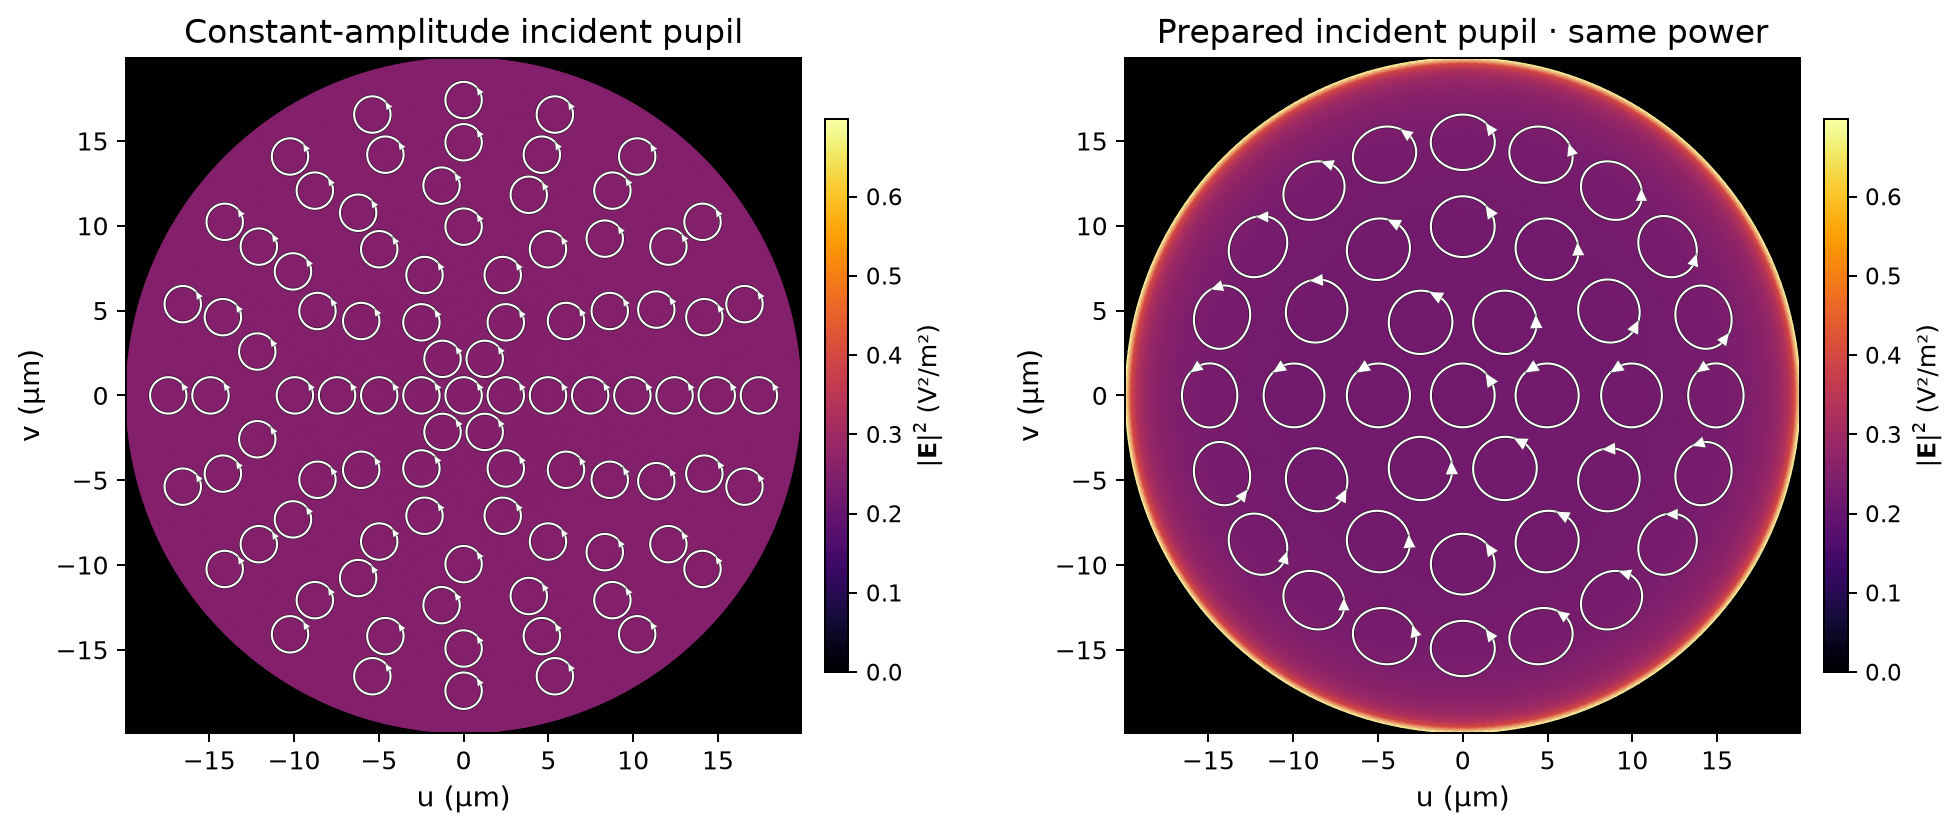

Each incident pupil carries 1.000 pW; C = 0.860456.
Uncompensated local pupil ellipse: minor/major = 0.504 to 1.000; ideal circular value = 1.


In [2]:
def interface_pupil(grid):
    local = (grid.points - grid.frame.origin) @ grid.frame.basis
    x, y = local[..., 0], local[..., 1]
    radius = np.hypot(x, y)
    phi = np.arctan2(y, x)
    sine_i = np.minimum(radius / focal_length, numerical_aperture / ni)
    ci = np.sqrt(1 - sine_i**2)
    co = np.sqrt(1 - (ni * sine_i / no) ** 2)
    ts, tp = transmission_coefficients(no, ni, co, ci)
    tau_s = ts * np.sqrt(ni * ci / (no * co))
    tau_p = tp * np.sqrt(ni * ci / (no * co))
    radial = np.stack((np.cos(phi), np.sin(phi)), axis=-1)
    azimuthal = np.stack((-np.sin(phi), np.cos(phi)), axis=-1)
    J = (
        tau_p[..., None, None] * radial[..., :, None] * radial[..., None, :]
        + tau_s[..., None, None] * azimuthal[..., :, None] * azimuthal[..., None, :]
    )

    return J, tau_s, tau_p


def prepare_illumination(count):
    coordinates = np.linspace(-1.1 * focal_length, 1.1 * focal_length, count)
    grid = optics.CartesianGrid(coordinates, coordinates)
    x, y = np.meshgrid(coordinates, coordinates)
    radius = np.hypot(x, y)
    outer_radius = focal_length * numerical_aperture / ni
    aperture = radius <= outer_radius
    area = np.sum(grid.weights[aperture])
    A0 = np.sqrt(2 * optics.Z0 * incident_power / (no * area))
    uniform = A0 * aperture[..., None] * polarization
    J, tau_s, tau_p = interface_pupil(grid)
    inverse = np.linalg.solve(J, uniform[..., None])[..., 0]
    C = np.sqrt(
        np.sum(abs(uniform) ** 2 * grid.weights[..., None])
        / np.sum(abs(inverse) ** 2 * grid.weights[..., None])
    )
    prepared = C * inverse

    return grid, uniform, prepared, J, C, aperture, tau_s, tau_p


grid, uniform, prepared, J, C, aperture, tau_s, tau_p = prepare_illumination(385)
input_uniform = optics.TransverseElectricField(grid, wavelength, uniform)
input_prepared = optics.TransverseElectricField(grid, wavelength, prepared)

for values in (uniform, prepared):
    power = no * np.sum(abs(values) ** 2 * grid.weights[..., None]) / (2 * optics.Z0)
    assert np.isclose(power, incident_power, rtol=2e-13, atol=0)

predicted_uniform = np.mean((abs(tau_p[aperture]) ** 2 + abs(tau_s[aperture]) ** 2) / 2)
predicted_compensated = 1 / np.mean(
    (1 / abs(tau_p[aperture]) ** 2 + 1 / abs(tau_s[aperture]) ** 2) / 2
)
assert np.isclose(C**2, predicted_compensated, rtol=2e-13)
assert C**2 <= predicted_uniform

# Evaluate the same analytic input on a polar chart for this pupil view.
# The focusing calculation above retains its Cartesian integration grid.
outer_radius = focal_length * numerical_aperture / ni
pupil_view = optics.PolarGrid(
    np.linspace(0, outer_radius, 65),
    np.arange(240) * 2 * np.pi / 240,
)
A0 = np.max(np.linalg.norm(uniform, axis=-1))
polar_uniform = np.broadcast_to(A0 * polarization, pupil_view.shape + (2,))
polar_J, _, _ = interface_pupil(pupil_view)
polar_prepared = C * np.linalg.solve(polar_J, polar_uniform[..., None])[..., 0]
input_uniform = optics.TransverseElectricField(pupil_view, wavelength, polar_uniform)
input_prepared = optics.TransverseElectricField(pupil_view, wavelength, polar_prepared)

figure, axes = plt.subplots(1, 2, figsize=(11, 5))
figure.subplots_adjust(left=0.07, right=0.93, bottom=0.14, top=0.89, wspace=0.42)
maximum = max(np.sum(abs(values) ** 2, axis=-1).max() for values in (uniform, prepared))
for axis, field, title in zip(
    axes,
    (input_uniform, input_prepared),
    ("Constant-amplitude incident pupil", "Prepared incident pupil · same power"),
):
    plot_intensity(
        field,
        axis=axis,
        norm=Normalize(0, maximum),
        cmap=intensity_cmap,
        title=title,
        min_intensity_fraction=0.002,
    )
    axis.set_facecolor("black")
plt.show()
print(f"Each incident pupil carries {incident_power * 1e12:.3f} pW; C = {C:.6f}.")

ratio = abs(tau_s[aperture] / tau_p[aperture])
print(
    f"Uncompensated local pupil ellipse: minor/major = {ratio.min():.3f} to {ratio.max():.3f}; ideal circular value = 1."
)

## 3. Compare the focal fields on a common absolute scale

The prepared illumination is applied **before** the same operator $J$ used for the constant-amplitude case. All three panels use the same physical focal grid and **linear absolute color scale**, with zero mapped to exact black. No gamma compression lifts weak intensity into mid-range colors. Local minima of total $|\mathbf E|^2$ can remain nonzero because the transverse and longitudinal components have different nodes; these minima are not forced to black. We evaluate the spectrum on a 257 × 257 window with 9.4 nm spacing; rendering resolution does not substitute for field evaluation. The white/black glyphs show transverse polarization on concentric rings. Automatic spacing resolves the bright core first; weaker rings use fewer angular positions, and changes in normalized Stokes state request additional detail. Glyph radii scale with projected intensity by default, with a readability floor. Only projected intensities below 0.2% of their peak are omitted. `scale_by_intensity=False` disables size scaling without changing the positions; `adaptive_density=False` disables density adaptation. Their arrows encode rotation without color.

The reference is lossless, so its higher intensity is expected. Agreement of a normalized shape alone would not establish equal throughput. Both are measured below.

Before focusing, the uncompensated circular state becomes elliptical with minor/major ratio $|\tau_s/\tau_p|$. This directly measures polarization aberration separately from total amplitude attenuation. Its numerical range is printed above; the ideal value is one.

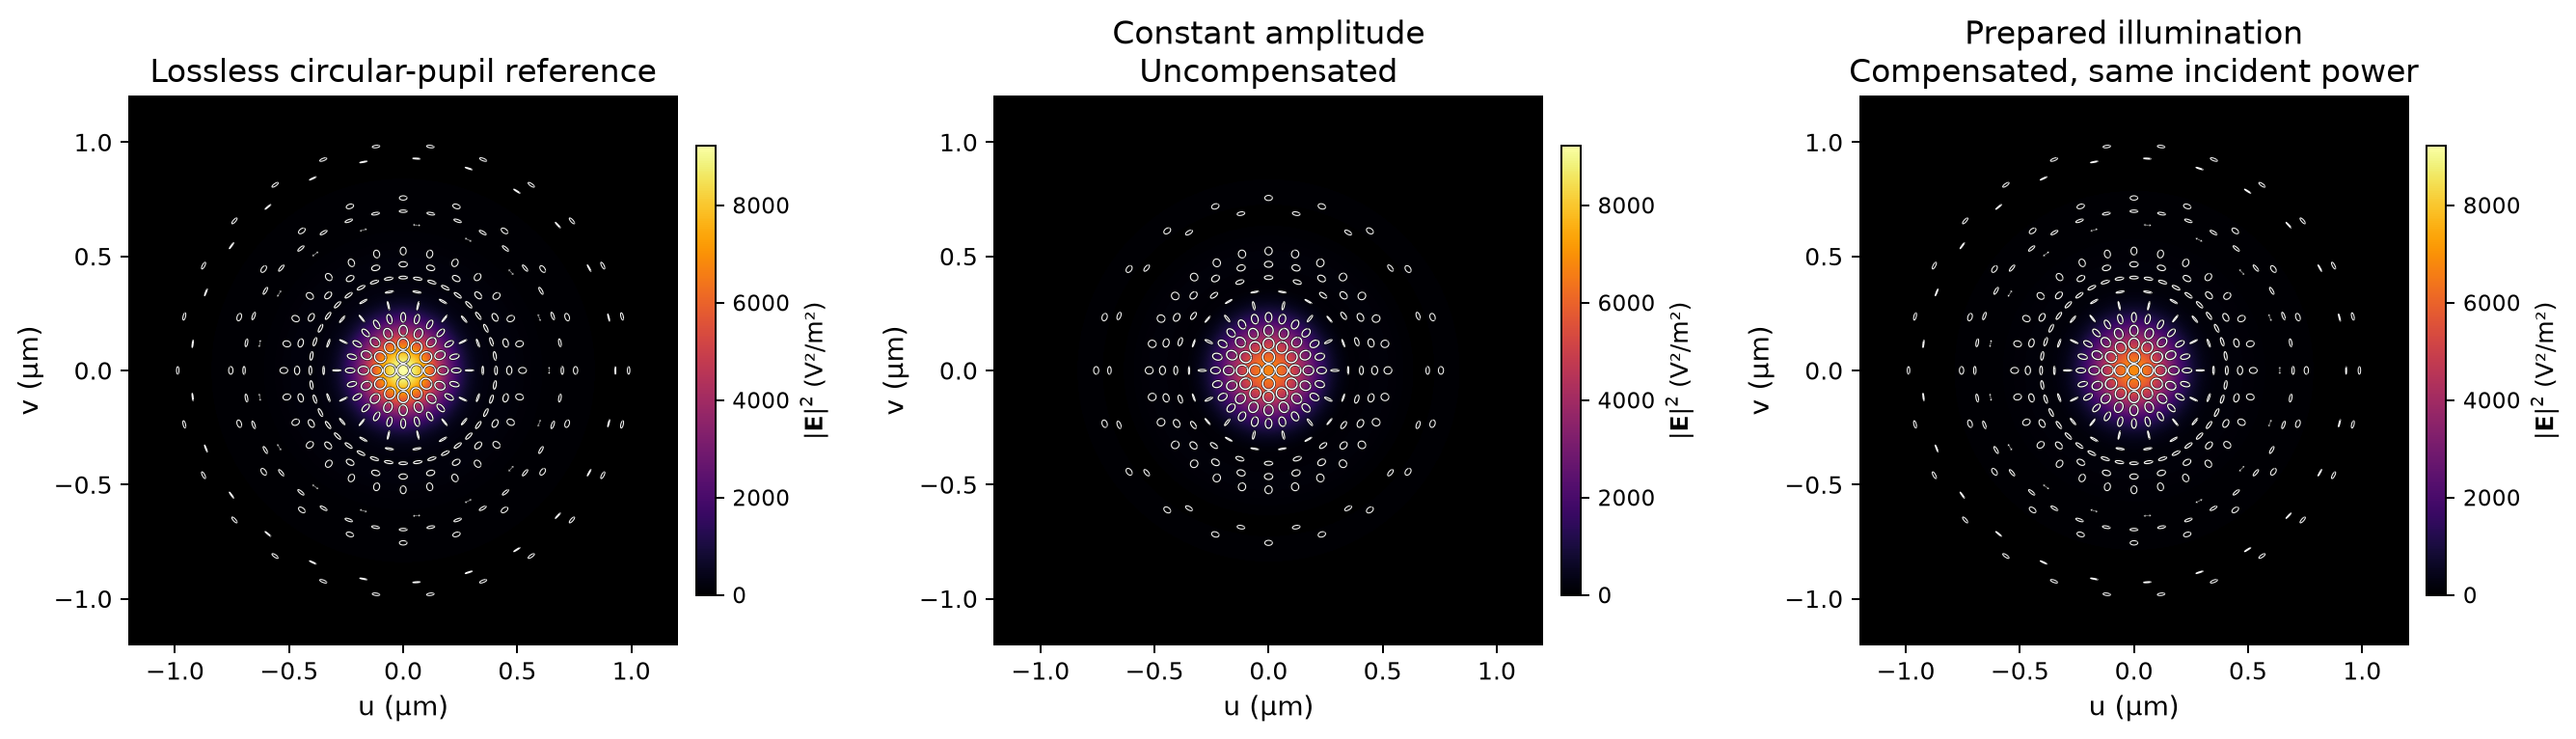

Circular-pupil reference: transmitted / incident power = 1.000000
Constant amplitude · uncompensated: transmitted / incident power = 0.794564
Prepared illumination · compensated: transmitted / incident power = 0.740384
||Ec - C Eideal|| / ||Eideal|| = 1.16e-14


In [3]:
pupils = {
    "Circular-pupil reference": uniform,
    "Constant amplitude · uncompensated": np.einsum("...ij,...j->...i", J, uniform),
    "Prepared illumination · compensated": np.einsum("...ij,...j->...i", J, prepared),
}
spectra = {}
fields = {}
focal_coordinates = np.linspace(-1.2 * um, 1.2 * um, 257)

for name, values in pupils.items():
    pupil = optics.TransverseElectricField(grid, wavelength, values)
    spectrum = focus_pupil(
        pupil,
        high_index,
        air,
        focal_length=focal_length,
        numerical_aperture=numerical_aperture,
    )
    spectra[name] = spectrum
    focal_grid = optics.CartesianGrid(
        focal_coordinates, focal_coordinates, spectrum.grid.frame
    )
    fields[name] = spectrum.evaluate(focal_grid, backend="nufft")

reference, uncorrected, corrected = fields.values()
maximum = reference.electric.norm2().max()
figure, axes = plt.subplots(1, 3, figsize=(15, 5.4))
figure.subplots_adjust(left=0.055, right=0.93, bottom=0.15, top=0.86, wspace=0.58)
for axis, field, title in zip(
    axes,
    fields.values(),
    (
        "Lossless circular-pupil reference",
        "Constant amplitude\nUncompensated",
        "Prepared illumination\nCompensated, same incident power",
    ),
):
    plot_intensity(
        field,
        axis=axis,
        norm=Normalize(0, maximum),
        cmap=intensity_cmap,
        title=title,
        distribution="polar",
    )
plt.show()

relative_complex_error = np.linalg.norm(
    corrected.electric.values - C * reference.electric.values
) / np.linalg.norm(reference.electric.values)
assert relative_complex_error < 1e-10
expected = (1, predicted_uniform, C**2)
for (name, spectrum), efficiency in zip(spectra.items(), expected):
    measured = spectrum.propagate(0).power() / incident_power
    assert np.isclose(measured, efficiency, rtol=2e-12)
    print(f"{name}: transmitted / incident power = {measured:.6f}")
print(f"||Ec - C Eideal|| / ||Eideal|| = {relative_complex_error:.3g}")

## 4. Separate the shape error from the power cost

The left profile retains absolute intensity. The right compares spatial shapes: each physical profile is normalized to its own peak, and the analytic scalar Airy pattern for a uniformly illuminated circular pupil is shown separately. The high-NA vector reference need not coincide exactly with that scalar pattern. For the uncompensated field we also report the best single complex factor $a=\langle E_{\rm ideal},E\rangle/\langle E_{\rm ideal},E_{\rm ideal}\rangle$. Its residual $\|E-aE_{\rm ideal}\|/\|E\|$ measures a distortion that no uniform gain or global phase can repair. This is a comparison of full complex vectors in the displayed window, not just on-axis intensity.

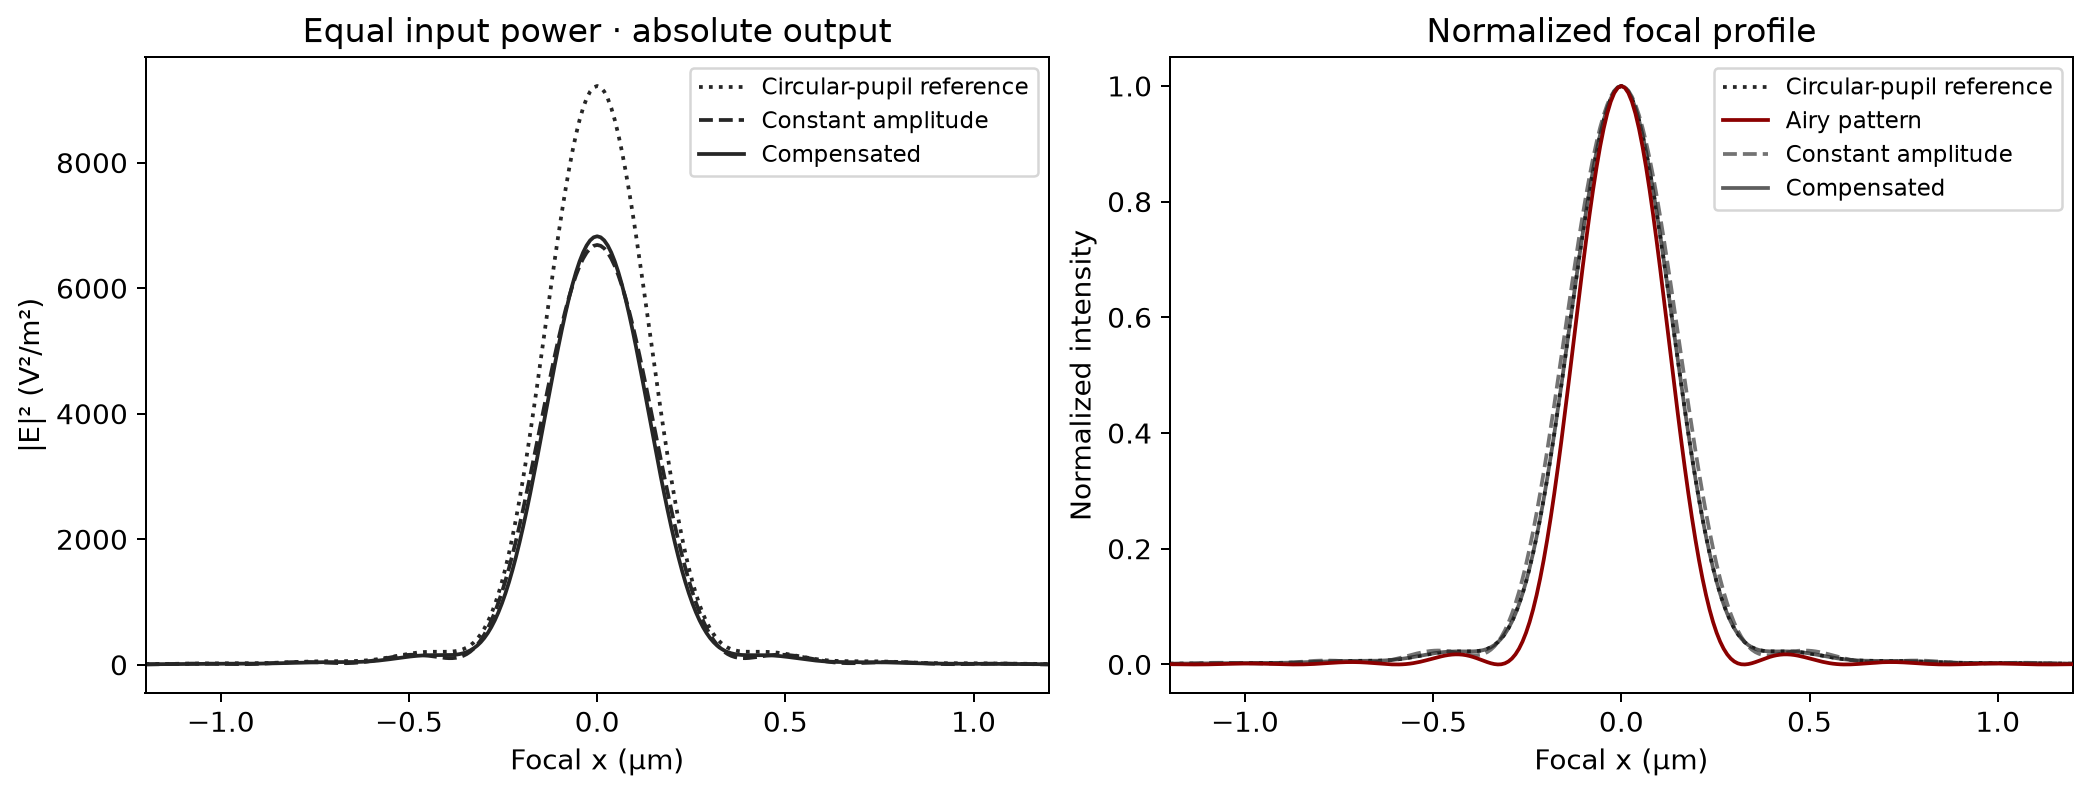

Circular-pupil reference: complex-vector shape error = 0.0000%
Constant amplitude · uncompensated: complex-vector shape error = 12.7406%
Prepared illumination · compensated: complex-vector shape error = 0.0000%


In [4]:
center = len(focal_coordinates) // 2
x = focal_coordinates / um
figure, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), layout="constrained")
for field, label, style, color, zorder in (
    (reference, "Circular-pupil reference", ":", "0.15", 2),
    (uncorrected, "Constant amplitude", "--", "0.15", 2),
    (corrected, "Compensated", "-", "0.15", 2),
):
    axes[0].plot(
        x, field.electric.norm2()[center], style, color=color, label=label, zorder=zorder
    )

ideal = reference.electric.norm2()[center]
axes[1].plot(x, ideal / ideal.max(), ":", color="0.15", label="Circular-pupil reference")
airy_argument = 2 * np.pi * numerical_aperture * abs(focal_coordinates) / wavelength
airy_amplitude = np.ones_like(airy_argument)
nonzero = airy_argument != 0
airy_amplitude[nonzero] = 2 * j1(airy_argument[nonzero]) / airy_argument[nonzero]
axes[1].plot(x, airy_amplitude**2, "-", color="#8B0000", label="Airy pattern", zorder=10)
axes[1].plot(
    x,
    uncorrected.electric.norm2()[center] / uncorrected.electric.norm2().max(),
    "--",
    color="0.45",
    label="Constant amplitude",
)
axes[1].plot(
    x,
    corrected.electric.norm2()[center] / corrected.electric.norm2().max(),
    "-",
    color="0.1",
    alpha=0.7,
    label="Compensated",
)
axes[0].set(ylabel="|E|² (V²/m²)", title="Equal input power · absolute output")
axes[1].set(ylabel="Normalized intensity", title="Normalized focal profile")
for axis in axes:
    axis.set(xlabel="Focal x (µm)", xlim=(-1.2, 1.2))
    axis.legend(fontsize=9)
plt.show()

ideal_vector = reference.electric.values.ravel()
for name, field in fields.items():
    vector = field.electric.values.ravel()
    a = np.vdot(ideal_vector, vector) / np.vdot(ideal_vector, ideal_vector)
    residual = np.linalg.norm(vector - a * ideal_vector) / np.linalg.norm(vector)
    print(f"{name}: complex-vector shape error = {residual:.4%}")

## 5. Check the pupil quadrature, and compose the channels analytically

An identity enforced by $J^{-1}$ does not verify the numerical diffraction integral. Refine the physical pupil independently, retaining its diameter, NA and incident power, and compare actual complex fields at focal probes. The sharp circular edge makes this a quadrature convergence check; no inference about a real objective's surface accuracy follows from it.

A different compensation strategy is to compose two pupils with exchanged principal axes. In the same transported $(p,s)$ basis,

$$
 J_1=\begin{pmatrix}\tau_p&0\\0&\tau_s\end{pmatrix},\quad
 J_2=\begin{pmatrix}\tau_s&0\\0&\tau_p\end{pmatrix},\quad
 J_2J_1=\tau_s\tau_p I.
$$

This removes *differential* transmission but leaves radial attenuation: it does not produce the lossless target. A physical arrangement must supply the required axis exchange and account for propagation, phase and changing ray directions. Merely putting two parallel dielectric interfaces in sequence does not exchange $s$ and $p$.

In [5]:
probe_x = np.linspace(-1.1, 1.1, 17) * um
points = np.column_stack(
    (probe_x, np.zeros_like(probe_x), np.full_like(probe_x, focal_length))
)
probes = optics.PointGrid(points)
reference_probe = (
    spectra["Constant amplitude · uncompensated"].evaluate(probes).electric.values
)
fine_grid, fine_uniform, _, fine_J, _, _, _, _ = prepare_illumination(577)
fine_values = np.einsum("...ij,...j->...i", fine_J, fine_uniform)
fine_spectrum = focus_pupil(
    optics.TransverseElectricField(fine_grid, wavelength, fine_values),
    high_index,
    air,
    focal_length=focal_length,
    numerical_aperture=numerical_aperture,
)
fine_probe = fine_spectrum.evaluate(probes).electric.values
quadrature_change = np.linalg.norm(fine_probe - reference_probe) / np.linalg.norm(
    fine_probe
)
print(
    f"385 → 577 pupil nodes per axis: complex focal-probe change = {quadrature_change:.3%}"
)
assert quadrature_change < 0.01

first = np.zeros(grid.shape + (2, 2), dtype=complex)
first[..., 0, 0], first[..., 1, 1] = tau_p, tau_s
second = first[..., ::-1, ::-1]
product = np.einsum("...ij,...jk->...ik", second, first)
assert np.allclose(product, (tau_s * tau_p)[..., None, None] * np.eye(2))

385 → 577 pupil nodes per axis: complex focal-probe change = 0.053%


**What this experiment establishes.** Analytic pupil preparation removes differential transmission and recovers the vector focal shape at a calculable throughput cost. The unchanged, constant-amplitude illumination provides the direct control. The Fresnel coefficients remain properties of the interface. Angle-dependent phase, absorption, pupil zeros and manufacturing constraints would require a new compensation analysis.

The prescribed pupil has the same role as the polarization pupil discussed in [Ansys's polarization analysis](https://optics.ansys.com/hc/en-us/articles/42661755401747-Investigating-OpticStudio-s-polarization-features); the results here are not a benchmark against that software.